# Session 5 · Advanced Supervised Learning: Time Series Analysis

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hamnakhan123/Diploma-in-Data-Science/blob/main/term-2/03-advanced-data-science-with-python/code/session-05-time-series-analysis.ipynb)

Diploma in Data Science · Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run the cells from top to bottom. Every example is self-contained, so you can also run any single cell on its own.

### Example 1 · Basic: building and decomposing a seasonal series

2016-01-01    157.5
2016-02-01    176.7
2016-03-01    211.3
2016-04-01    236.1
2016-05-01    252.4
2016-06-01    272.7
2016-07-01    279.4
2016-08-01    258.2
2016-09-01    217.8
2016-10-01    188.8
2016-11-01    175.8
2016-12-01    175.0
2017-01-01    168.5
2017-02-01    207.3
Freq: MS

seasonal index by month (1.00 = average):
Jan    0.770
Feb    0.869
Mar    1.000
Apr    1.102
May    1.194
Jun    1.276
Jul    1.226
Aug    1.160
Sep    1.005
Oct    0.861
Nov    0.777
Dec    0.759


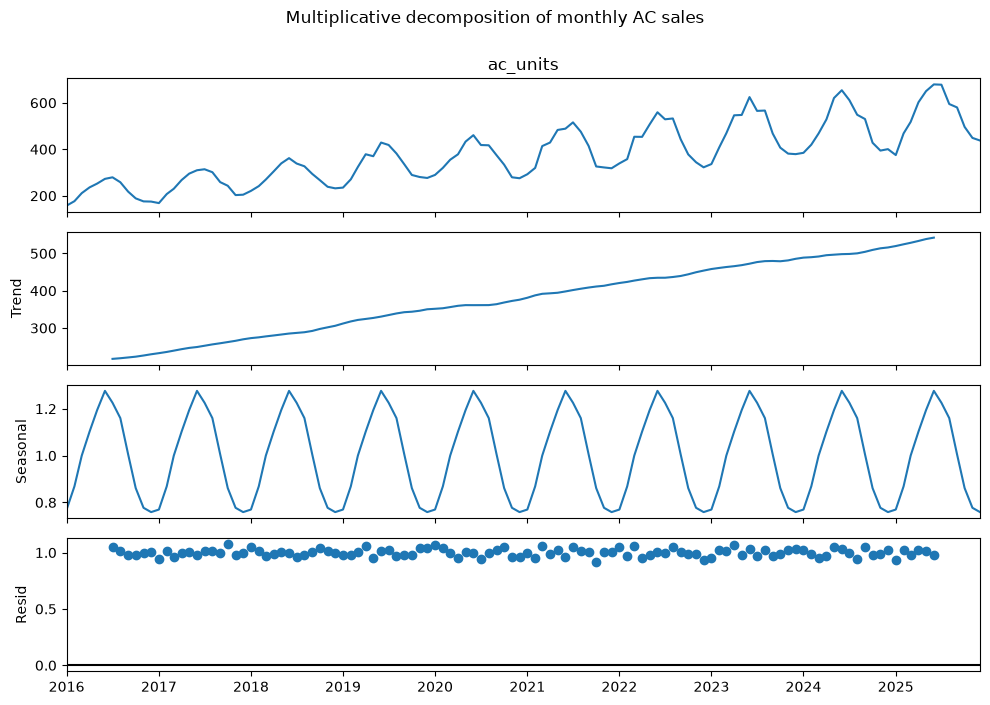

In [1]:
"""Create a monthly sales series with trend + yearly seasonality + noise and decompose it."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

rng = np.random.default_rng(0)
idx = pd.date_range("2016-01-01", periods=120, freq="MS")           # 10 years, month starts
t = np.arange(120)
season = 1 + 0.25 * np.sin(2 * np.pi * (t - 2) / 12)                  # summer peak
sales = (200 + 3 * t) * season * np.exp(rng.normal(0, 0.04, 120))     # multiplicative
y = pd.Series(sales.round(1), index=idx, name="ac_units")
print(y.head(14).to_string())

res = seasonal_decompose(y, model="multiplicative", period=12)
print("\nseasonal index by month (1.00 = average):")
print(res.seasonal[:12].round(3).set_axis([d.strftime("%b") for d in idx[:12]]).to_string())

fig = res.plot(); fig.set_size_inches(10, 7)
fig.suptitle("Multiplicative decomposition of monthly AC sales", y=1.0)
fig.tight_layout(); fig.savefig("session-05_decomposition.png", dpi=100); plt.show()

### Example 2 · Intermediate: stationarity, differencing and ACF/PACF

random walk (price)          ADF stat   -1.72  p-value 0.4226  -> NOT stationary
first difference (returns)   ADF stat  -18.01  p-value 0.0000  -> stationary
AR(2) process                ADF stat  -15.21  p-value 0.0000  -> stationary
ACF  lags 1-5: [ 0.48  0.01 -0.17 -0.15 -0.05]
PACF lags 1-5: [ 0.48 -0.29 -0.06 -0.03  0.02]  <- cuts off after lag 2


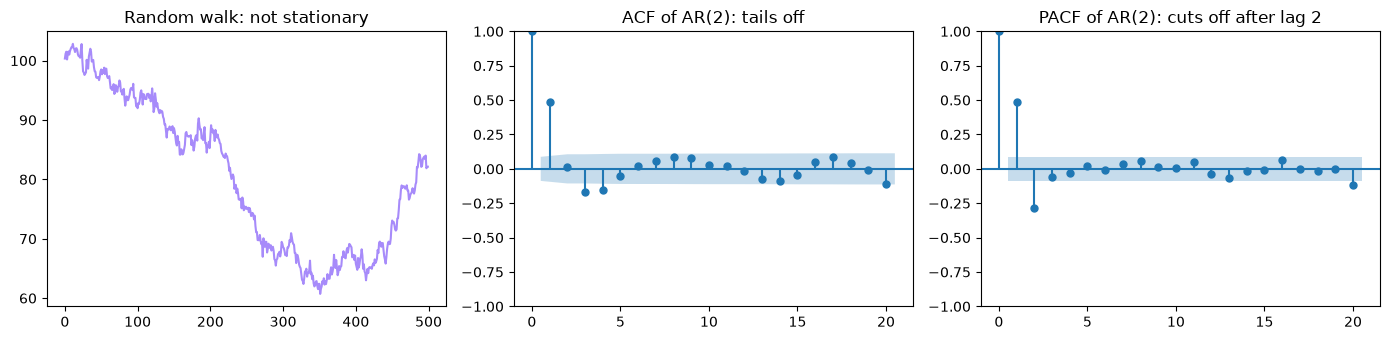

In [2]:
"""ADF test before and after differencing, and ACF/PACF plots of an AR(2) process."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

rng = np.random.default_rng(1)
# A random walk (non-stationary): a share price
walk = pd.Series(100 + np.cumsum(rng.normal(0, 1, 500)))
def adf(s, name):
    stat, p = adfuller(s.dropna())[:2]
    print(f"{name:<28} ADF stat {stat:7.2f}  p-value {p:.4f}  -> {'stationary' if p < .05 else 'NOT stationary'}")
adf(walk, "random walk (price)")
adf(walk.diff(), "first difference (returns)")

# An AR(2) process: y_t = 0.6 y_{t-1} - 0.3 y_{t-2} + e_t
e = rng.normal(0, 1, 600); ar = np.zeros(600)
for i in range(2, 600):
    ar[i] = 0.6 * ar[i - 1] - 0.3 * ar[i - 2] + e[i]
ar = pd.Series(ar[100:])
adf(ar, "AR(2) process")
print("ACF  lags 1-5:", acf(ar, nlags=5)[1:].round(2))
print("PACF lags 1-5:", pacf(ar, nlags=5)[1:].round(2), " <- cuts off after lag 2")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].plot(walk, color="#A78BFA"); ax[0].set_title("Random walk: not stationary")
plot_acf(ar, lags=20, ax=ax[1], title="ACF of AR(2): tails off")
plot_pacf(ar, lags=20, ax=ax[2], title="PACF of AR(2): cuts off after lag 2", method="ywm")
fig.tight_layout(); fig.savefig("session-05_acf_pacf.png", dpi=100); plt.show()

### Example 3 · Intermediate: fitting ARIMA and choosing orders by AIC

In [3]:
"""Grid-search ARIMA orders by AIC, check residuals with Ljung-Box, forecast with intervals."""
import itertools
import warnings
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
warnings.filterwarnings("ignore")

rng = np.random.default_rng(2)
# Weekly demand with a gentle trend and AR(1) behaviour
n = 156
e = rng.normal(0, 8, n); y = np.zeros(n)
for i in range(1, n):
    y[i] = 0.7 * y[i - 1] + e[i]
y = pd.Series(500 + 1.5 * np.arange(n) + y, index=pd.date_range("2023-01-01", periods=n, freq="W"))
train, test = y[:-12], y[-12:]

results = []
for p, d, q in itertools.product(range(3), range(2), range(3)):
    try:
        m = ARIMA(train, order=(p, d, q), trend="t" if d == 1 else "ct").fit()
        results.append(((p, d, q), m.aic))
    except Exception:
        pass
results.sort(key=lambda r: r[1])
print("best 5 orders by AIC:")
for order, aic in results[:5]:
    print(f"  ARIMA{order}  AIC = {aic:.1f}")

best_order = results[0][0]
model = ARIMA(train, order=best_order, trend="t" if best_order[1] == 1 else "ct").fit()
lb = acorr_ljungbox(model.resid, lags=[10])
print(f"\nLjung-Box p-value on residuals: {lb['lb_pvalue'].iloc[0]:.3f}  (> 0.05 = residuals look like white noise)")
fc = model.get_forecast(12)
out = pd.DataFrame({"actual": test.round(0), "forecast": fc.predicted_mean.round(0)})
out[["low95", "high95"]] = fc.conf_int().round(0).values
print(out.head(6).to_string())
mae = (out.actual - out.forecast).abs().mean(); naive = (test - train.iloc[-1]).abs().mean()
print(f"\nMAE ARIMA = {mae:.1f}   MAE naive (last value) = {naive:.1f}")

best 5 orders by AIC:
  ARIMA(2, 0, 1)  AIC = 994.3
  ARIMA(2, 0, 2)  AIC = 996.5
  ARIMA(1, 1, 1)  AIC = 996.9
  ARIMA(2, 1, 1)  AIC = 998.5
  ARIMA(1, 1, 2)  AIC = 998.6



Ljung-Box p-value on residuals: 0.988  (> 0.05 = residuals look like white noise)
            actual  forecast  low95  high95
2025-10-05   703.0     714.0  700.0   728.0
2025-10-12   714.0     715.0  699.0   731.0
2025-10-19   709.0     716.0  699.0   733.0
2025-10-26   727.0     718.0  701.0   734.0
2025-11-02   725.0     719.0  702.0   736.0
2025-11-09   734.0     721.0  704.0   738.0

MAE ARIMA = 6.1   MAE naive (last value) = 9.9


### Example 4 · Advanced: SARIMA vs Holt-Winters vs seasonal naive

model                         MAE   RMSE  MAPE %  MASE
Seasonal naive               46.5   49.9     8.6  1.00
Simple exp. smoothing       147.7  173.0    25.0  3.17
Holt (trend)                172.1  195.6    29.5  3.70
Holt-Winters (mult.)         19.6   21.8     3.8  0.42
SARIMA(1,1,1)(0,1,1,12)      14.5   20.9     2.8  0.31

Holt-Winters smoothing parameters: alpha=0.00, beta=0.00, gamma=0.00


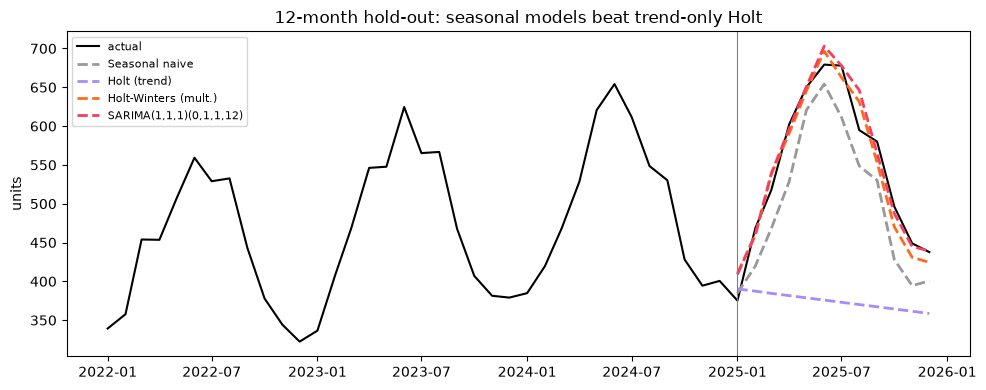

In [4]:
"""Compare seasonal naive, Holt, Holt-Winters and SARIMA on a 12-month hold-out; plot the forecasts."""
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.filterwarnings("ignore")

rng = np.random.default_rng(0)
idx = pd.date_range("2016-01-01", periods=120, freq="MS"); t = np.arange(120)
y = pd.Series((200 + 3 * t) * (1 + 0.25 * np.sin(2 * np.pi * (t - 2) / 12)) * np.exp(rng.normal(0, .04, 120)), index=idx)
train, test = y[:-12], y[-12:]

fc = {
    "Seasonal naive": pd.Series(train[-12:].values, index=test.index),
    "Simple exp. smoothing": SimpleExpSmoothing(train, initialization_method="estimated").fit().forecast(12),
    "Holt (trend)": ExponentialSmoothing(initialization_method="estimated", endog=train, trend="add").fit().forecast(12),
    "Holt-Winters (mult.)": ExponentialSmoothing(initialization_method="estimated", endog=train, trend="add", seasonal="mul", seasonal_periods=12).fit().forecast(12),
    "SARIMA(1,1,1)(0,1,1,12)": SARIMAX(np.log(train), order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
                               .forecast(12).pipe(np.exp),
}
naive_mae = (test - fc["Seasonal naive"]).abs().mean()
print(f"{'model':<26}{'MAE':>7}{'RMSE':>7}{'MAPE %':>8}{'MASE':>6}")
for name, f in fc.items():
    err = test - f
    print(f"{name:<26}{err.abs().mean():>7.1f}{np.sqrt((err ** 2).mean()):>7.1f}"
          f"{(err.abs() / test).mean() * 100:>8.1f}{err.abs().mean() / naive_mae:>6.2f}")

hw = ExponentialSmoothing(initialization_method="estimated", endog=train, trend="add", seasonal="mul", seasonal_periods=12).fit()
# Parameters near 0 mean the pattern is so regular that the model barely updates its initial level, trend and season
print(f"\nHolt-Winters smoothing parameters: alpha={hw.params['smoothing_level']:.2f}, "
      f"beta={hw.params['smoothing_trend']:.2f}, gamma={hw.params['smoothing_seasonal']:.2f}")

plt.figure(figsize=(10, 4))
plt.plot(y[-48:], color="black", label="actual")
for name, c in [("Seasonal naive", "#999999"), ("Holt (trend)", "#A78BFA"), ("Holt-Winters (mult.)", "#FF6B1A"), ("SARIMA(1,1,1)(0,1,1,12)", "#F43F5E")]:
    plt.plot(fc[name], ls="--", lw=2, color=c, label=name)
plt.axvline(test.index[0], color="grey", lw=.8); plt.legend(fontsize=8); plt.ylabel("units")
plt.title("12-month hold-out: seasonal models beat trend-only Holt")
plt.tight_layout(); plt.savefig("session-05_forecast_comparison.png", dpi=110); plt.show()

### Example 5 · Advanced: rolling-origin evaluation and ML with lag features

In [5]:
"""Rolling-origin CV with TimeSeriesSplit: Holt-Winters vs gradient boosting on lag features."""
import warnings
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import HistGradientBoostingRegressor
from statsmodels.tsa.holtwinters import ExponentialSmoothing
warnings.filterwarnings("ignore")

rng = np.random.default_rng(5)
idx = pd.date_range("2024-01-01", periods=730, freq="D"); t = np.arange(730)
temp = 28 + 7 * np.sin(2 * np.pi * (t - 100) / 365) + rng.normal(0, 1.5, 730)        # exogenous driver
load = 900 + 0.3 * t + 25 * (temp - 28) + np.where(idx.dayofweek == 6, -120, 0) + rng.normal(0, 25, 730)
df = pd.DataFrame({"load": load, "temp": temp}, index=idx)
for L in [1, 7, 14]:
    df[f"lag_{L}"] = df["load"].shift(L)
df["dow"] = df.index.dayofweek
df["roll7"] = df["load"].shift(1).rolling(7).mean()
df = df.dropna()
features = ["temp", "lag_1", "lag_7", "lag_14", "dow", "roll7"]

tscv = TimeSeriesSplit(n_splits=4, test_size=30)
print("fold  train days  HW MAE  GBM MAE  seasonal-naive MAE")
for k, (tr, te) in enumerate(tscv.split(df), 1):
    train, test = df.iloc[tr], df.iloc[te]
    hw = ExponentialSmoothing(initialization_method="estimated", endog=train["load"], trend="add", seasonal="add", seasonal_periods=7).fit().forecast(len(test))
    gbm = HistGradientBoostingRegressor(random_state=0).fit(train[features], train["load"])
    p = gbm.predict(test[features])            # one-step-ahead: lags are known each morning
    sn = test["lag_7"]
    print(f"{k:>4}  {len(train):>10}  {np.mean(np.abs(test.load - hw.values)):>6.1f}  "
          f"{np.mean(np.abs(test.load - p)):>7.1f}  {np.mean(np.abs(test.load - sn)):>18.1f}")

fold  train days  HW MAE  GBM MAE  seasonal-naive MAE


   1         596    36.5     39.1                54.1


   2         626    58.9     40.8                49.6


   3         656    48.3     59.7                47.9


   4         686    53.5     55.6                64.7


### 🏙️ Real-life data problem: monthly electricity demand for a distribution company

data: Jan 2015 to Dec 2025, 132 months; average 1974 GWh


best SARIMA(0, 1, 1)(1, 1, 1, 12) with AIC -433.8  (searched 24 models)


SARIMA                   validation MAPE = 2.45%
Holt-Winters             validation MAPE = 2.25%
Seasonal naive + growth  validation MAPE = 3.90%



Purchase plan for the next 12 months:
           forecast_GWh  upper95_GWh
Jan 2026        1911.0       2017.0
Feb 2026        1981.0       2092.0
Mar 2026        2260.0       2386.0
Apr 2026        2632.0       2779.0
May 2026        2998.0       3165.0
Jun 2026        3212.0       3391.0
Jul 2026        3143.0       3318.0
Aug 2026        2951.0       3116.0
Sep 2026        2781.0       2936.0
Oct 2026        2431.0       2567.0
Nov 2026        2133.0       2252.0
Dec 2026        1976.0       2086.0

annual total: 30,409 GWh (plan for up to 32,105 GWh)


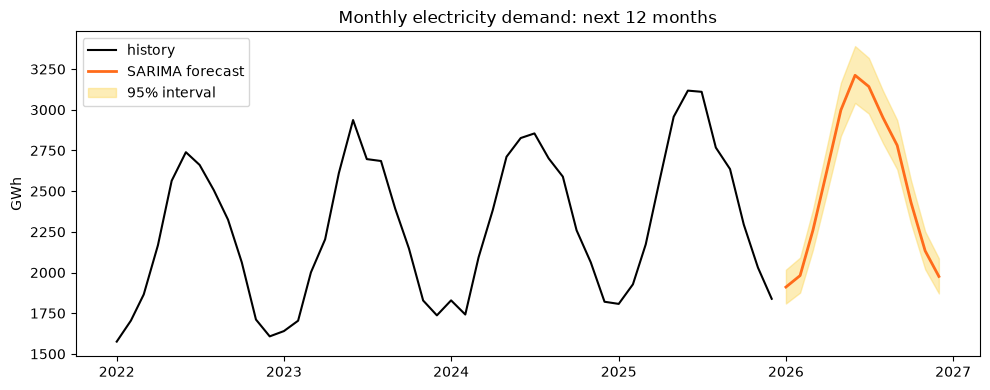

In [6]:
"""Real-life problem: 12-month electricity demand forecast with SARIMA order search, validation and intervals."""
import itertools
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
warnings.filterwarnings("ignore")

rng = np.random.default_rng(42)
idx = pd.date_range("2015-01-01", periods=132, freq="MS"); t = np.arange(132)
summer = np.array([0.80, 0.82, 0.92, 1.05, 1.22, 1.30, 1.25, 1.20, 1.12, 0.98, 0.85, 0.79])
gwh = pd.Series((1500 * 1.045 ** (t / 12)) * summer[idx.month - 1] * np.exp(rng.normal(0, .03, 132)), index=idx)
gwh.iloc[63] *= 1.12                                              # one heat-wave month
train, test = gwh[:-12], gwh[-12:]
print(f"data: {gwh.index[0]:%b %Y} to {gwh.index[-1]:%b %Y}, {len(gwh)} months; average {gwh.mean():.0f} GWh")

# Search small SARIMA orders on log data by AIC
cands = []
for p, q, P, Q in itertools.product([0, 1, 2], [0, 1], [0, 1], [0, 1]):
    try:
        m = SARIMAX(np.log(train), order=(p, 1, q), seasonal_order=(P, 1, Q, 12)).fit(disp=False)
        cands.append((m.aic, (p, 1, q), (P, 1, Q, 12)))
    except Exception:
        pass
cands.sort()
aic, order, sorder = cands[0]
print(f"best SARIMA{order}{sorder} with AIC {aic:.1f}  (searched {len(cands)} models)")

sar = SARIMAX(np.log(train), order=order, seasonal_order=sorder).fit(disp=False)
f_sar = np.exp(sar.forecast(12))
f_hw = ExponentialSmoothing(initialization_method="estimated", endog=train, trend="add", seasonal="mul", seasonal_periods=12).fit().forecast(12)
f_sn = pd.Series(train[-12:].values * (train[-12:].sum() / train[-24:-12].sum()), index=test.index)  # naive + growth
for name, f in [("SARIMA", f_sar), ("Holt-Winters", f_hw), ("Seasonal naive + growth", f_sn)]:
    print(f"{name:<24} validation MAPE = {(np.abs(test - f) / test).mean() * 100:.2f}%")

final = SARIMAX(np.log(gwh), order=order, seasonal_order=sorder).fit(disp=False)
fc = final.get_forecast(12)
plan = pd.DataFrame({"forecast_GWh": np.exp(fc.predicted_mean), "upper95_GWh": np.exp(fc.conf_int().iloc[:, 1])}).round(0)
plan.index = plan.index.strftime("%b %Y")
print("\nPurchase plan for the next 12 months:\n", plan.to_string())
print(f"\nannual total: {plan.forecast_GWh.sum():,.0f} GWh (plan for up to {plan.upper95_GWh.sum():,.0f} GWh)")

ci = np.exp(fc.conf_int())
plt.figure(figsize=(10, 4))
plt.plot(gwh[-48:], color="black", label="history")
plt.plot(np.exp(fc.predicted_mean), color="#FF6B1A", lw=2, label="SARIMA forecast")
plt.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color="#FCD34D", alpha=.4, label="95% interval")
plt.ylabel("GWh"); plt.title("Monthly electricity demand: next 12 months"); plt.legend()
plt.tight_layout(); plt.savefig("session-05_power_forecast.png", dpi=110); plt.show()

### 🧩 Mini project: restaurant daily covers forecaster

In [7]:
"""Mini project: 14-day restaurant demand forecast and staffing plan (Holt-Winters vs SARIMAX vs naive)."""
import warnings
import numpy as np
import pandas as pd
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.filterwarnings("ignore")

rng = np.random.default_rng(9)
idx = pd.date_range("2025-09-01", periods=420, freq="D")
dow_effect = np.array([0.8, 0.75, 0.8, 0.9, 1.25, 1.45, 1.3])        # Mon..Sun
holiday = pd.Series(0, index=idx); holiday[idx[::45]] = 1               # a public holiday roughly every 45 days
covers = (120 + 0.05 * np.arange(420)) * dow_effect[idx.dayofweek] * (1 + 0.35 * holiday.values) \
         * np.exp(rng.normal(0, .07, 420))
y = pd.Series(covers.round(), index=idx)
train, test = y[:-14], y[-14:]
hol_tr, hol_te = holiday[:-14].to_frame("hol"), holiday[-14:].to_frame("hol")

f_naive = pd.Series(train[-7:].tolist() * 2, index=test.index)
f_hw = ExponentialSmoothing(initialization_method="estimated", endog=train, trend="add", seasonal="mul", seasonal_periods=7).fit().forecast(14)
sx = SARIMAX(np.log(train), exog=hol_tr, order=(1, 0, 1), seasonal_order=(1, 1, 1, 7), trend="c").fit(disp=False)
f_sx = np.exp(sx.forecast(14, exog=hol_te))
for name, f in [("Seasonal naive", f_naive), ("Holt-Winters", f_hw), ("SARIMAX + holiday", f_sx)]:
    print(f"{name:<18} MAE = {np.abs(test - f).mean():5.1f} covers/day")

# Refit SARIMAX on all data (near-tied with Holt-Winters, and it can use the holiday flag) and plan 14 days (no holidays ahead)
future_idx = pd.date_range(y.index[-1] + pd.Timedelta(days=1), periods=14, freq="D")
final = SARIMAX(np.log(y), exog=holiday.to_frame("hol"), order=(1, 0, 1), seasonal_order=(1, 1, 1, 7), trend="c").fit(disp=False)
fc = np.exp(final.forecast(14, exog=pd.DataFrame({"hol": 0}, index=future_idx)))
plan = pd.DataFrame({"day": future_idx.strftime("%a %d %b"), "covers": fc.round().astype(int).values})
plan["waiters_needed"] = np.ceil(plan["covers"] / 25).astype(int)     # one waiter per 25 covers
print("\n" + plan.to_string(index=False))

Seasonal naive     MAE =  12.8 covers/day
Holt-Winters       MAE =  10.3 covers/day
SARIMAX + holiday  MAE =  10.6 covers/day



       day  covers  waiters_needed
Mon 26 Oct     115               5
Tue 27 Oct     107               5
Wed 28 Oct     113               5
Thu 29 Oct     128               6
Fri 30 Oct     176               8
Sat 31 Oct     208               9
Sun 01 Nov     184               8
Mon 02 Nov     116               5
Tue 03 Nov     108               5
Wed 04 Nov     114               5
Thu 05 Nov     128               6
Fri 06 Nov     176               8
Sat 07 Nov     208               9
Sun 08 Nov     184               8
